# v2 checks (2026-11-16)

First v2 trained models: `_p5_n10000` × `_biasnoisenestv2_p9_n320000` × `_noisefly`, P+P_gm at kp0.35/kpgm0.25, using the v1 best hyperparameters (`best-rand30v1_nbest{0,1,2}`, transferred from the v1 sweep, not re-tuned).

**Question:** which parameters to predict. Every model varies all 14 parameters in training, and the question is only which of them the NPE outputs.
- **noise in θ (11):** Ω_c, σ8, b1, b2, b_s², b_∇ and the five noise amplitudes $A_n$.
- **no noise in θ (6):** Ω_c, σ8 and the four biases. The network learns the posterior already marginalized over $A_n$.

**Summary:**
- **SHAMe and the phase-matched mock agree closely** for both choices (section 1). So the remaining galaxy-formation mismatch is a small fraction of σ.
- **Noise vs no noise in θ give the same posterior means.** They agree to ≤0.2σ, with Ω_c and σ8 ~0.4–0.6σ high and b1 ~0.6–0.9σ low for both. On this one SHAMe mock, no noise in θ is ~10–20% tighter in b1. That tightening doesn't hold up on the coverage set: there the median posterior widths are equal (section 5).
- **Seeds scatter as much as hyperparameter sets** (section 3). Single-seed comparisons between nbest0/1/2 aren't meaningful at this level. Averaged over 3 seeds, nbest0 has the lowest validation loss. The v1 rank-10 and rank-20 trials are clearly worse (by 1–3 nats), so the coarse v1 ranking carries over to v2.
- **Coverage (100 inner points, section 5): every model and every ensemble is calibrated** within the ±2σ binomial band in Ω_c, σ8 and b1, slightly on the conservative side. Noise vs no noise in θ makes no difference to calibration or width, whether we ensemble over seeds or over hyperparameter sets. So we keep the **noise amplitudes in θ**, which also gives us posteriors on them.
- **The data constrain combinations of the noise amplitudes** (section 4). The 1D marginals look prior-like because of strong degeneracies, and because of the exact global sign symmetry $A_n \to -A_n$.
- **Dropped: predicting h, Ω_b and n_s** (`allcosmo`, `plite: false`). Their posteriors are prior-dominated (σ/σ_prior ≈ 0.8–0.9). Predicting them costs ~10–15% in σ8 and ~15–35% in σ(b1), doesn't change the offsets, and adds seed scatter. The long version of this notebook, with those plots and the per-density tables, is at `/scratch/kstoreyf/muchisimocks/nbexec/backup/2026-11-16_v2_checks_long_executed.ipynb`.

In [1]:
import os
import sys
from pathlib import Path

os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import numpy as np
import matplotlib.pyplot as plt

import data_loader
import plotter
import paths

%load_ext autoreload
%autoreload 2

FIG_DIR = REPO_ROOT / "figures" / "2026-11-16_v2_checks"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("results:", paths.DIR_RESULTS)

results: /scratch/kstoreyf/muchisimocks/results_v2


In [2]:
import pandas as pd

DIR_SBI = Path(paths.DIR_RESULTS) / "results_sbi"
TAG_MODEL = "sbi_muchisimocks_pk_pgm_kp0.35_kpgm0.25_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand30v1_nbest"
TAG_MOCK = "_nbar0.00022"   # SHAMe density the matched mock is built for
M_TAG = "samples_test_muchisimocks_pk_pgm_kp0.35_kpgm0.25_shamematched_p0_n10_biasshame_noisebest_p0_n1_noisematched"
# paper palette: P+P_gm = light green (plotter_figs.COLORS_FID[1]); navy for the second chain in each comparison
COLOR_PKPGM, COLOR_PKPGM_DARK = "#6BB756", "#1F2F6B"   # light green, navy
COLOR_SHAME, COLOR_MATCHED = COLOR_PKPGM, COLOR_PKPGM_DARK
COLOR_NOISE, COLOR_NONOISE = COLOR_PKPGM, COLOR_PKPGM_DARK
SEED_SUFFIX = {0: "", 1: "_seed1", 2: "_seed2"}
PN_SHARED = ["omega_cold", "sigma8_cold", "b1", "b2", "bs2", "bl"]
PN_LABELS = {"omega_cold": r"$\Omega_{\rm c}$", "sigma8_cold": r"$\sigma_8$", "b1": r"$b_1$"}
EXTENTS_SM = {"omega_cold": (0.24, 0.38), "sigma8_cold": (0.76, 0.89), "b1": (0.15, 0.7),
              "b2": (-0.9, 0.7), "bs2": (-1.9, 1.9), "bl": (-10, 10)}
NBAR_LABEL = r"$\bar{n}=2.2\times10^{-4}$"

def _load(d, fname):
    f = d / fname
    if not f.exists():
        return None
    names = list(np.loadtxt(d / "param_names.txt", dtype=str))
    s = np.load(f)
    return (s[:, 0, :] if s.ndim == 3 else s), names

def model_dir(suffix):
    # suffix "0", "1_nonoise_seed2", ... is appended after "nbest"; v1-sweep trials ("v1rank10_<id>") replace "nbest"
    return DIR_SBI / (f"{TAG_MODEL[:-len('nbest')]}{suffix}" if suffix.startswith("v1rank") else f"{TAG_MODEL}{suffix}")

def load_test(suffix, test):
    # test: "shame" (SHAMe 2.2e-4) or "matched" (phase-matched, mean statistic over 10 noise realizations)
    d = model_dir(suffix)
    fname = f"samples_test_shame_pk_pgm_kp0.35_kpgm0.25{TAG_MOCK}_pred.npy" if test == "shame" else f"{M_TAG}_mean_pred.npy"
    return _load(d, fname)

def mixture_2d(sl, seed=0):
    # equal-weight mixture of (samples, names) with identical param_names
    names = sl[0][1]
    assert all(list(s[1]) == list(names) for s in sl)
    rng = np.random.default_rng(seed)
    n = min(len(s[0]) for s in sl) // len(sl)
    return np.concatenate([s[0][rng.choice(len(s[0]), n, replace=False)] for s in sl]), names

def ensemble(noise, test, nb=0):
    # 3-seed mixture of hyperparameter set nb; noise in {"", "_nonoise"}
    sl = [load_test(f"{nb}{noise}{SEED_SUFFIX[s]}", test) for s in (0, 1, 2)]
    return None if any(x is None for x in sl) else mixture_2d(sl)

TRUTH = {k: float(v) for k, v in data_loader.load_params_ood("shame", TAG_MOCK).items() if k in PN_SHARED}
print("truth (SHAMe 2.2e-4; also the matched mock's truth):", {k: round(v, 3) for k, v in TRUTH.items()})

import utils_inference
import matplotlib.colors as mcolors

def contours(samples_list, labels, colors, shades, linewidths, title, fn_save,
             sigma_lines=(), loc_legend=(0.35, 1.0)):
    # sigma_lines: indices of chains whose 1D 68% interval (16/84th percentiles) is drawn as thin solid lines
    fig = plotter.plot_contours_inf(
        param_names=PN_SHARED, idx_obs=0, theta_obs_true=None,
        inf_methods=["sbi"] * len(samples_list), tags_inf=[f"c{i}" for i in range(len(samples_list))],
        tags_test=[""] * len(samples_list), samples_list=samples_list, labels=labels, colors=colors,
        linestyles=["-"] * len(samples_list), shades=shades, bar_shades=shades, linewidths=linewidths,
        unreparameterize=True, add_truth=True, truth_locations=[TRUTH], truth_colors=["k"],
        extents=EXTENTS_SM, figsize=(10, 10), fontsize_legend=14, title=title,
        legend_location=(0, 1), legend_loc="upper left", loc_legend=loc_legend, show=False,
    )
    if fig is None:
        return
    diag = {ax.get_subplotspec().colspan.start: ax for ax in fig.axes
            if ax.get_subplotspec().rowspan.start == ax.get_subplotspec().colspan.start}
    for i in sigma_lines:
        arr, names = utils_inference.unreparameterize_theta(*samples_list[i])
        names = list(names)
        for j, p in enumerate(PN_SHARED):
            ax = diag[j]
            # this chain's 1D marginal curve in the panel; lines stop at the curve, like the 1σ shading
            curves = [l for l in ax.get_lines() if len(l.get_xdata()) > 10
                      and np.allclose(mcolors.to_rgba(l.get_color())[:3], mcolors.to_rgba(colors[i])[:3])]
            x_c, y_c = (np.asarray(curves[0].get_xdata()), np.asarray(curves[0].get_ydata())) if curves else (None, None)
            for q in np.percentile(arr[:, names.index(p)], [16, 84]):
                y_top = np.interp(q, x_c, y_c) if curves else ax.get_ylim()[1]
                ax.vlines(q, 0, y_top, color=colors[i], ls="-", lw=0.8)
    fig.savefig(FIG_DIR / fn_save, bbox_inches="tight")
    plt.show()


truth (SHAMe 2.2e-4; also the matched mock's truth): {'sigma8_cold': 0.816, 'omega_cold': 0.309, 'b1': 0.474, 'b2': 0.032, 'bs2': -0.085, 'bl': -0.824}


## 1. SHAMe vs phase-matched mock (nbest0, 3-seed ensemble)

The posterior for each mock is the equal-weight mixture of nbest0 seeds 0, 1 and 2. The matched mock uses the SHAMe Rings initial conditions (seed −406168, mean over the 0/π phase pair), populated with our perturbative bias model at the SHAMe biases plus the best-fit noise. It uses the mean statistic over its 10 noise realizations. Black dashed lines mark the truth, which is the same for both mocks. Thin solid navy lines in the 1D panels mark the matched mock's 68% interval (16th–84th percentiles), and the light-green shading marks SHAMe's. For noise in θ, a SHAMe-only version comes first.

The two mocks share their phases, so the gap between the contours is the galaxy-formation mismatch between SHAMe and our forward model. The offset of the matched contour from truth is that phase's cosmic variance plus network error.

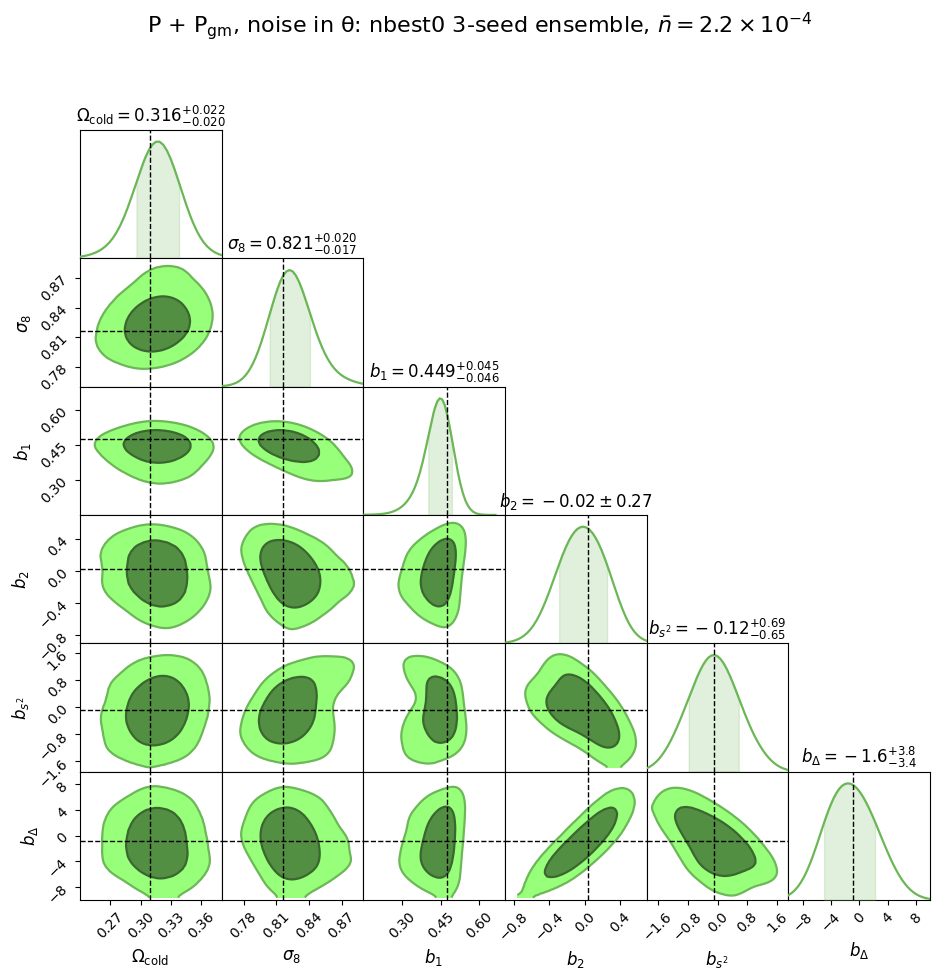

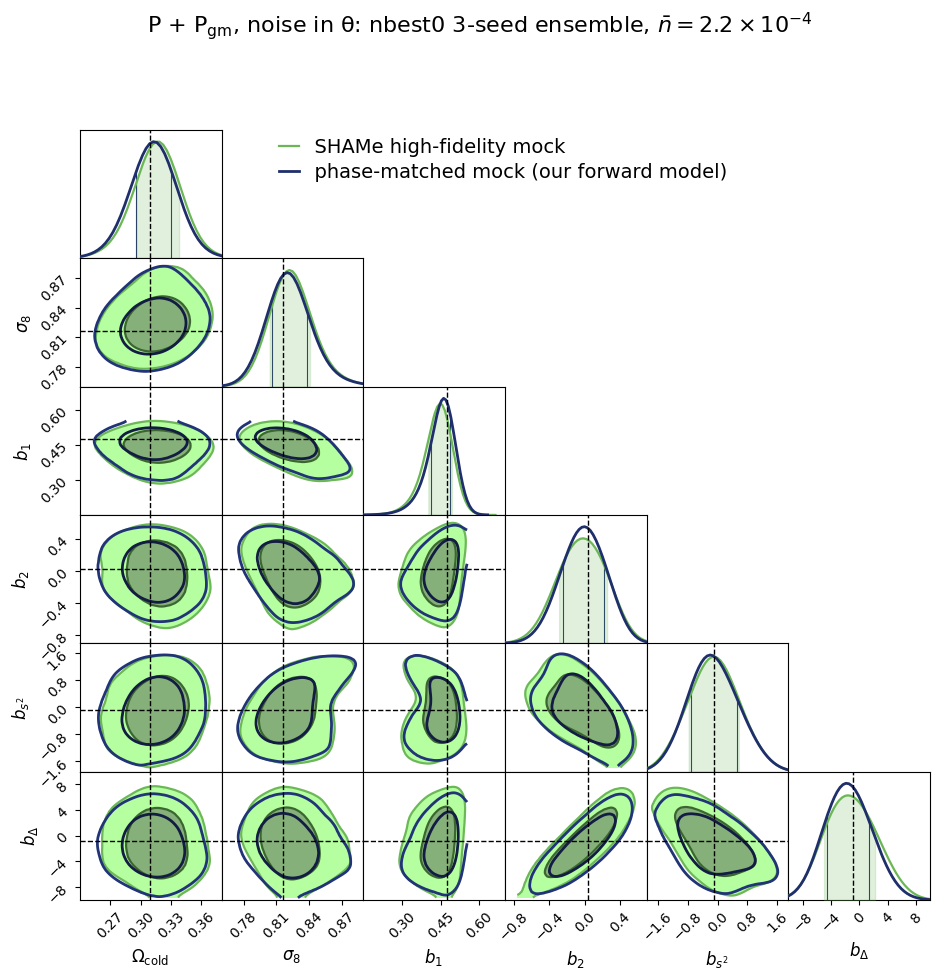

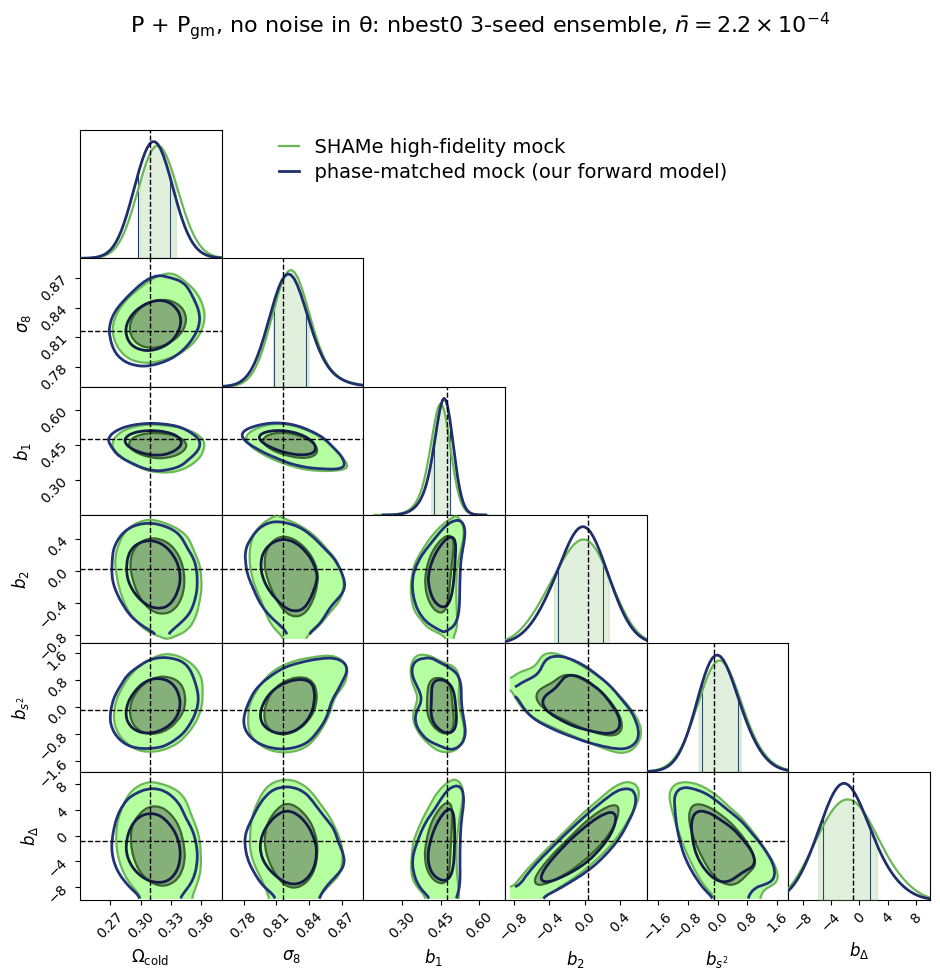

In [3]:
LAB_SHAME, LAB_MATCHED = "SHAMe high-fidelity mock", "phase-matched mock (our forward model)"
for noise, lab in (("", "noise in θ"), ("_nonoise", "no noise in θ")):
    sh, mm = ensemble(noise, "shame"), ensemble(noise, "matched")
    if sh is None or mm is None:
        print(f"{lab}: missing seeds"); continue
    title = f"P + P$_{{\\rm gm}}$, {lab}: nbest0 3-seed ensemble, {NBAR_LABEL}"
    tag = noise or "_noise"
    if noise == "":   # SHAMe-only version first (for building up the comparison)
        contours([sh], [LAB_SHAME], [COLOR_SHAME], [True], [1.6], title,
                 f"contours_shame_ens3seed_nbest0{tag}.pdf")
    contours([sh, mm], [LAB_SHAME, LAB_MATCHED], [COLOR_SHAME, COLOR_MATCHED], [True, False], [1.6, 2.0],
             title, f"contours_shame_vs_matched_ens3seed_nbest0{tag}.pdf", sigma_lines=[1])

## 2. Noise in θ vs no noise in θ (nbest0, 3-seed ensembles)

Same ensembles as section 1, overplotted by parameter choice, with one figure per mock. Noise in θ is light green (filled). No noise in θ is navy (outlines), with thin solid lines marking its 1D 68% interval.

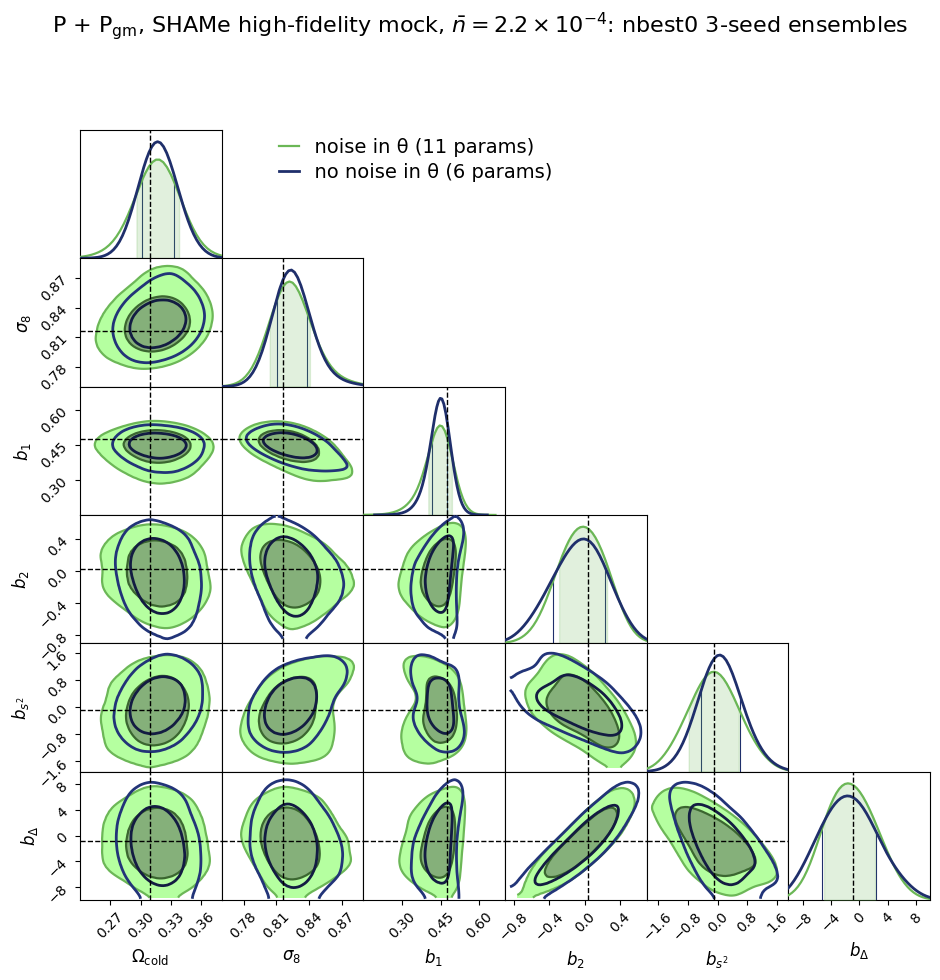

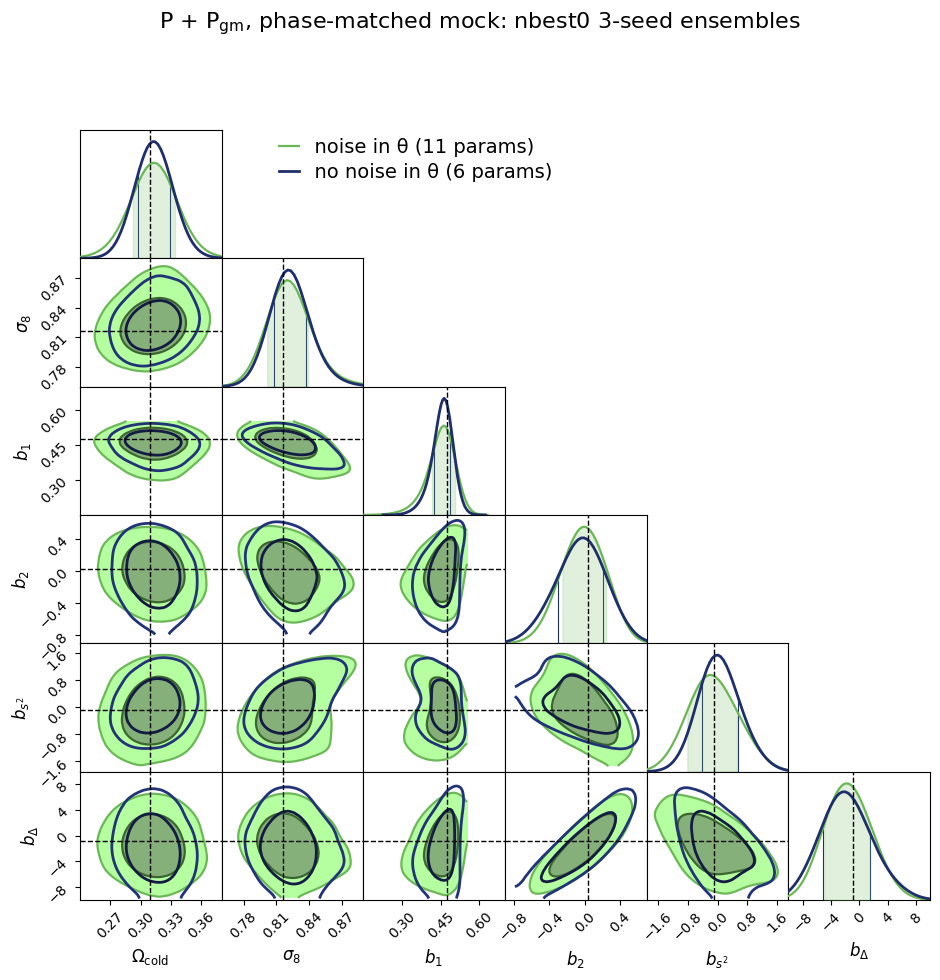

In [4]:
for test, tlab in (("shame", f"SHAMe high-fidelity mock, {NBAR_LABEL}"), ("matched", "phase-matched mock")):
    a, b = ensemble("", test), ensemble("_nonoise", test)
    if a is None or b is None:
        print(f"{tlab}: missing seeds"); continue
    contours([a, b], ["noise in θ (11 params)", "no noise in θ (6 params)"], [COLOR_NOISE, COLOR_NONOISE],
             [True, False], [1.6, 2.0], f"P + P$_{{\\rm gm}}$, {tlab}: nbest0 3-seed ensembles",
             f"contours_noise_vs_nonoise_ens3seed_nbest0_{test}.pdf", sigma_lines=[1])

In [5]:
# numbers behind sections 1-2: (posterior mean − truth)/σ and σ, physical b1
rows = []
for test in ("shame", "matched"):
    for noise, lab in (("", "noise in θ"), ("_nonoise", "no noise in θ")):
        e = ensemble(noise, test)
        if e is None:
            continue
        arr, names = e
        s8 = arr[:, names.index("sigma8_cold")]
        x = {"omega_cold": arr[:, names.index("omega_cold")], "sigma8_cold": s8, "b1": arr[:, names.index("sigma8_cold_x_b1")] / s8}
        row = {"test": test, "model": lab}
        for k, v in x.items():
            row[(k, "Δ/σ")] = (v.mean() - TRUTH[k]) / v.std()
            row[(k, "σ")] = v.std()
        rows.append(row)
df = pd.DataFrame(rows).set_index(["test", "model"])
df.columns = pd.MultiIndex.from_tuples(df.columns)
df.round(3)

omega_cold        sigma8_cold            b1       
                             Δ/σ      σ         Δ/σ      σ    Δ/σ      σ
test    model                                                           
shame   noise in θ         0.366  0.019       0.498  0.018 -0.849  0.043
        no noise in θ      0.536  0.016       0.609  0.015 -0.877  0.034
matched noise in θ         0.192  0.019       0.380  0.018 -0.563  0.044
        no noise in θ      0.264  0.016       0.462  0.016 -0.547  0.034

## 3. Seeds vs hyperparameter sets

Each point is one network: (posterior mean − truth)/σ and posterior σ for Ω_c, σ8 and b1. nbest0/1/2 each have seeds 0–2. The last two columns are a rank-10 and a rank-20 trial from the v1 sweep (noise in θ, seed 0), retrained here to check that the v1 ranking carries over to v2. Filled light-green points are noise in θ and open navy points are no noise in θ. The table gives the best validation loss (sbi's "best validation performance", the NLL, lower is better); compare within a column only, since the two columns predict different parameter sets.


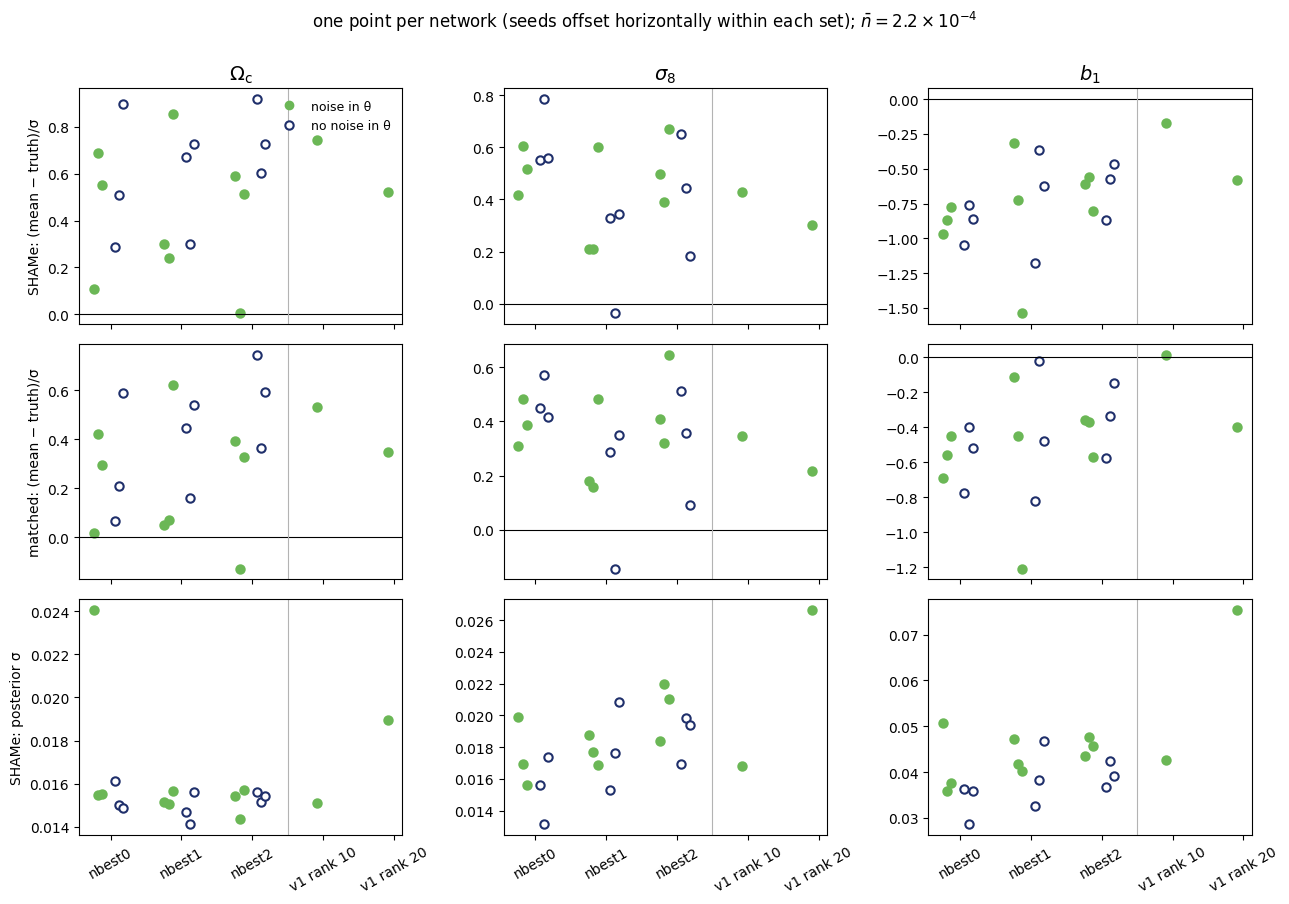

best validation loss (NLL, lower = better); v1 sweep order was nbest0 −2.81 < nbest1 −2.70 < nbest2 −2.61 (old data)
seed mean ± std (noise in θ): {'nbest0': '0.179 ± 0.207', 'nbest1': '0.551 ± 0.083', 'nbest2': '0.609 ± 0.324'}


noise in θ  no noise in θ
hyperparameters   seed                           
nbest0            0          0.364         -7.425
                  1         -0.044         -7.512
                  2          0.217         -7.423
nbest1            0          0.534         -7.314
                  1          0.641         -7.334
                  2          0.478         -7.262
nbest2            0          0.390         -7.496
                  1          0.456         -7.324
                  2          0.981         -7.316
v1rank10_nfcvgas4 0          1.339            NaN
v1rank20_qiost01x 0          2.982            NaN

In [6]:
import re, glob
from matplotlib.lines import Line2D
def phys_stats(s):
    arr, names = s
    s8 = arr[:, names.index("sigma8_cold")]
    x = [arr[:, names.index("omega_cold")], s8, arr[:, names.index("sigma8_cold_x_b1")] / s8]
    return np.array([(v.mean() - TRUTH[k]) / v.std() for v, k in zip(x, ["omega_cold", "sigma8_cold", "b1"])]), np.array([v.std() for v in x])

SEEDS_ALL = (0, 1, 2, 3)
SFX_SEED = lambda sd: "" if sd == 0 else f"_seed{sd}"
V1RANK = ["v1rank10_nfcvgas4", "v1rank20_qiost01x"]   # v1-sweep trials ranked 10 and 20, noise in θ, seed 0
XLAB = ["nbest0", "nbest1", "nbest2", "v1 rank 10", "v1 rank 20"]
nets = [(nb, f"{nb}{noise}{SFX_SEED(sd)}", noise, sd) for nb in (0, 1, 2) for noise in ("", "_nonoise") for sd in SEEDS_ALL]
nets += [(3 + i, t, "", 0) for i, t in enumerate(V1RANK)]

fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for x, sfx, noise, sd in nets:
    color = COLOR_NOISE if noise == "" else COLOR_NONOISE
    x0 = x + (-0.15 if noise == "" else 0.15) * (x < 3) + 0.06 * (sd - 1.5)
    for r, test in enumerate(("shame", "matched")):
        s = load_test(sfx, test)
        if s is None:
            continue
        d, sig = phys_stats(s)
        kw = dict(color=color, ms=6, mfc=color if noise == "" else "white", mew=1.5)
        for c in range(3):
            axes[r, c].plot(x0, d[c], "o", **kw)
            if r == 0:
                axes[2, c].plot(x0, sig[c], "o", **kw)
for c, k in enumerate(["omega_cold", "sigma8_cold", "b1"]):
    axes[0, c].set_title(PN_LABELS[k], fontsize=14)
    for r in (0, 1):
        axes[r, c].axhline(0, color="k", lw=0.8)
    for r in range(3):
        axes[r, c].axvline(2.5, color="0.7", lw=0.8)
    axes[2, c].set_xticks(range(5)); axes[2, c].set_xticklabels(XLAB, rotation=30)
axes[0, 0].set_ylabel("SHAMe: (mean − truth)/σ")
axes[1, 0].set_ylabel("matched: (mean − truth)/σ")
axes[2, 0].set_ylabel("SHAMe: posterior σ")
axes[0, 0].legend(handles=[Line2D([], [], marker="o", ls="", color=COLOR_NOISE, label="noise in θ"),
                           Line2D([], [], marker="o", ls="", color=COLOR_NONOISE, mfc="white", mew=1.5, label="no noise in θ")],
                  fontsize=9, frameon=False)
fig.suptitle(f"one point per network (seeds offset horizontally within each set); {NBAR_LABEL}", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "seeds_vs_nbest_offsets.pdf", bbox_inches="tight")
plt.show()

# best validation loss per network, parsed from the training logs
val = {}
for f in glob.glob("/scratch/kstoreyf/muchisimocks/logs_v2/*.out"):
    t = open(f, errors="ignore").read()
    m, v = re.search(r"^train: \S*best-rand30v1_((?:nbest|v1rank)\S+?)\.yaml", t, re.M), re.findall(r"Best validation performance: (\S+)", t)
    if m and v:
        val[m.group(1)] = float(v[-1])
rows = []
for nb in (0, 1, 2):
    for sd in SEEDS_ALL:
        r_ = {"hyperparameters": f"nbest{nb}", "seed": sd}
        for noise, lab in (("", "noise in θ"), ("_nonoise", "no noise in θ")):
            r_[lab] = val.get(f"nbest{nb}{noise}{SFX_SEED(sd)}", np.nan)
        rows.append(r_)
for t in V1RANK:
    rows.append({"hyperparameters": t, "seed": 0, "noise in θ": val.get(t, np.nan), "no noise in θ": np.nan})
df_val = pd.DataFrame(rows).set_index(["hyperparameters", "seed"]).dropna(how="all")
print("best validation loss (NLL, lower = better); v1 sweep order was nbest0 −2.81 < nbest1 −2.70 < nbest2 −2.61 (old data)")
print("seed mean ± std (noise in θ):", {f"nbest{nb}": f"{df_val.loc[f'nbest{nb}', 'noise in θ'].mean():.3f} ± {df_val.loc[f'nbest{nb}', 'noise in θ'].std():.3f}" for nb in (0, 1, 2)})
df_val.round(3)


## 4. All predicted parameters with noise in θ (matched mock)

The triangle plot shows all 11 predicted parameters for the three nbest0 seeds with noise in θ, unreparameterized to physical biases and amplitudes. Every truth is known exactly for the matched mock (`params_fixed_biasshame_noisebest_p0_n1`).

- **The noise amplitudes are strongly degenerate.** A_homog–A_b1 and A_b1–A_b2 are anticorrelated, and A_homog–A_b2 is positively correlated. The truth (2.0, −2.0, 1.0) lies along those ridges, inside the 2σ contours but away from the 1D peaks. So the data constrain combinations of the noise amplitudes, while the 1D marginals look prior-like through projection.
- **There is an exact global sign symmetry.** Flipping every $A_n$ is the same as ε → −ε, which leaves the statistics' distribution unchanged. So (A) and (−A) fit equally well, and the merged mirror solutions also pull the 1D marginals toward 0.
- **The noise is nearly uncorrelated with Ω_c, σ8 and b1,** so marginalizing over it costs little.
- **Seed 0 is wider than seeds 1 and 2** in Ω_c and b1. It is the worst-fit network (validation loss 0.36 vs −0.04 and 0.22).

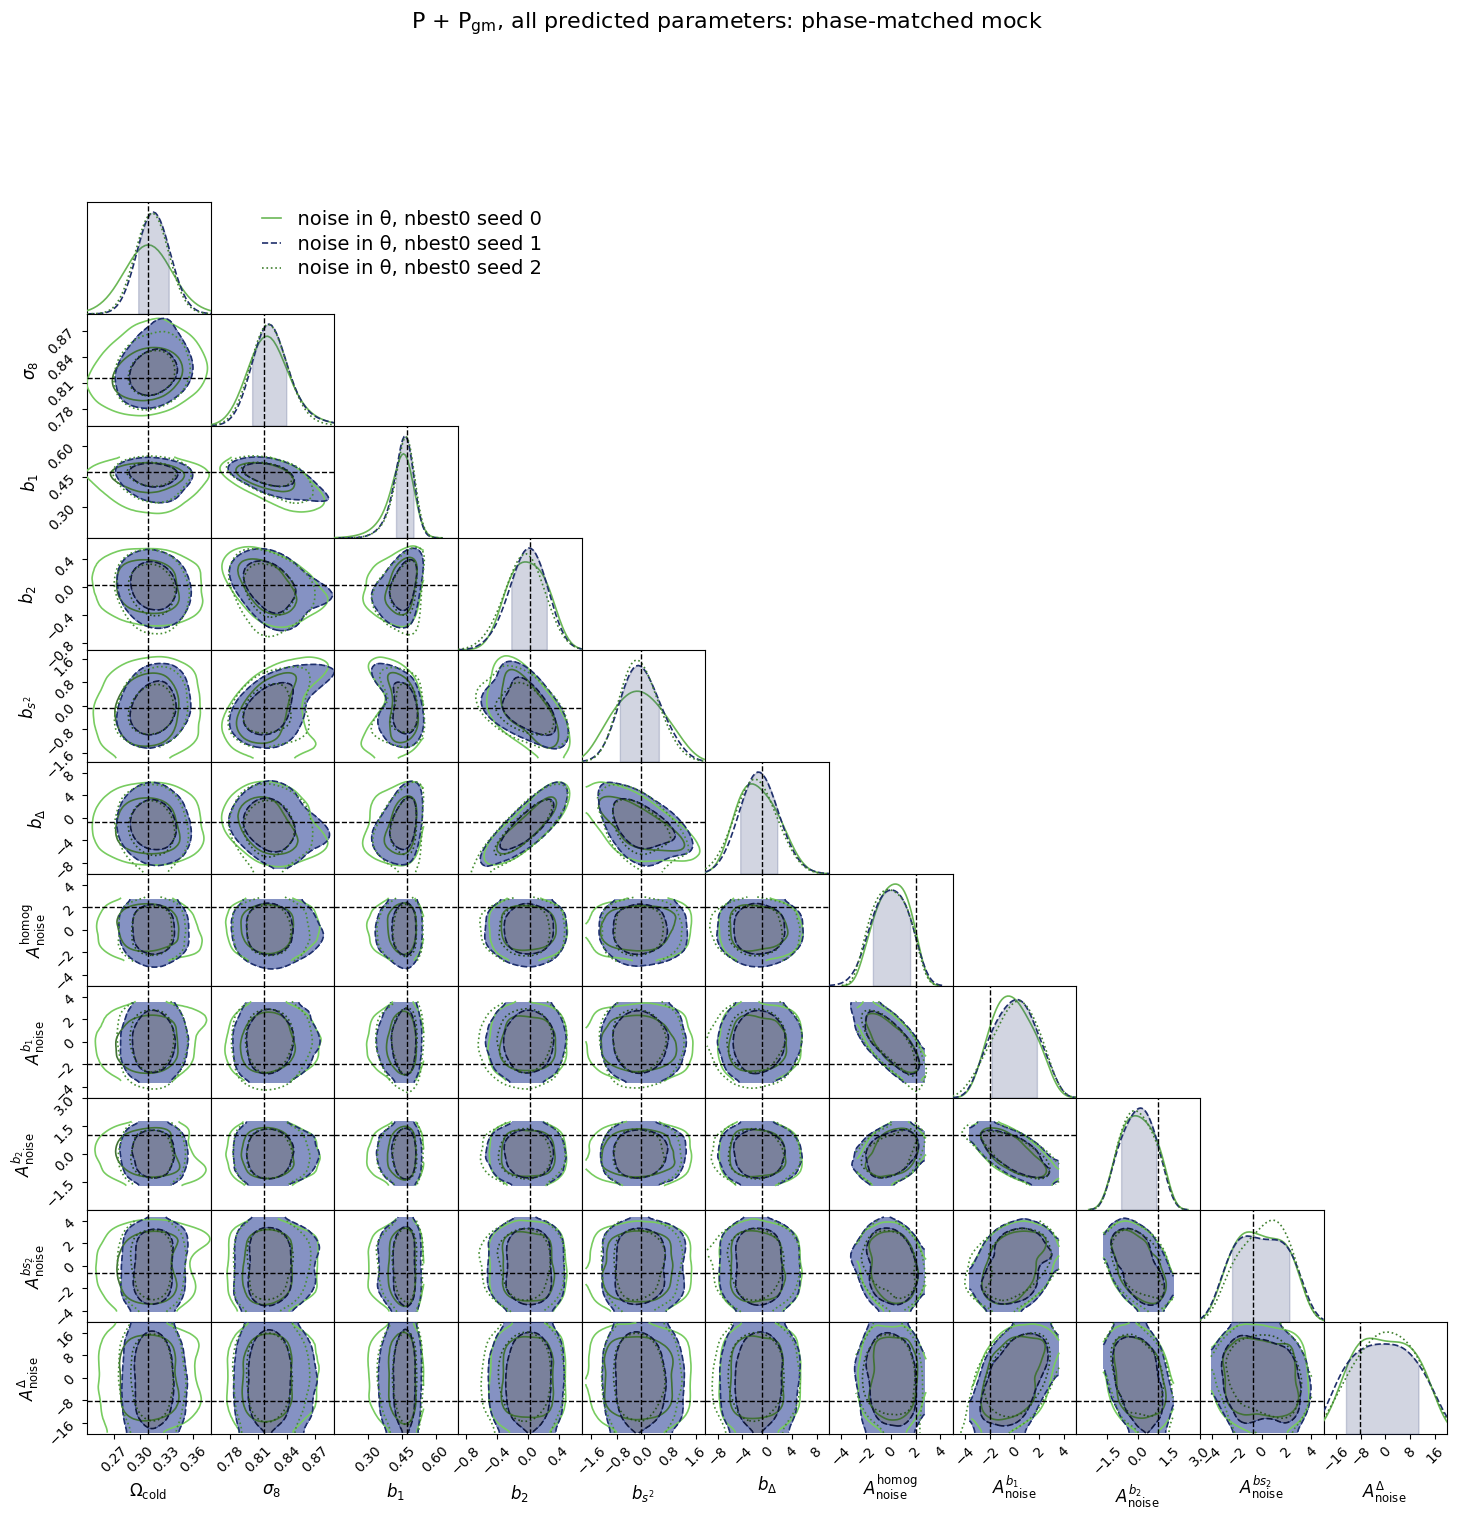

In [7]:
NOISE_NAMES = ["An_homog", "An_b1", "An_b2", "An_bs2", "An_bl"]
PRIOR_A = {"An_homog": (-5, 5), "An_b1": (-5, 5), "An_b2": (-3, 3), "An_bs2": (-5, 5), "An_bl": (-20, 20)}
PN_ALL = PN_SHARED + NOISE_NAMES
_mt = pd.read_csv(REPO_ROOT / "data" / "params" / "params_fixed_biasshame_noisebest_p0_n1.txt").iloc[0].to_dict()
truth_all = {"omega_cold": TRUTH["omega_cold"], "sigma8_cold": TRUTH["sigma8_cold"], **{k: float(_mt[k]) for k in PN_ALL[2:]}}
sl = [load_test(f"0{SEED_SUFFIX[sd]}", "matched") for sd in (0, 1, 2)]
fig = plotter.plot_contours_inf(
    param_names=PN_ALL, idx_obs=0, theta_obs_true=None,
    inf_methods=["sbi"] * 3, tags_inf=["s0", "s1", "s2"], tags_test=[""] * 3,
    samples_list=sl, labels=[f"noise in θ, nbest0 seed {sd}" for sd in (0, 1, 2)], colors=[COLOR_PKPGM, COLOR_PKPGM_DARK, "#3F7F2F"],
    linestyles=["-", "--", ":"], shades=[False, True, False], linewidths=[1.2] * 3,
    unreparameterize=True, add_truth=True, truth_locations=[truth_all], truth_colors=["k"],
    extents={**EXTENTS_SM, **PRIOR_A}, figsize=(16, 16), fontsize_legend=14,
    title="P + P$_{\\rm gm}$, all predicted parameters: phase-matched mock",
    legend_location=(0, 1), legend_loc="upper left", loc_legend=(0.35, 1.0), show=False,
)
if fig is not None:
    fig.savefig(FIG_DIR / "contours_allparams_nbest0_seeds_matched.pdf", bbox_inches="tight")
plt.show()

## 5. Coverage on the v2 coverage set (quick subset)

Test set `_coveragev2_p5_n1000 × _biasnoisecoveragev2_p9_n1000 × _noisefly`, with independent IC phases. To get results quickly we use a subset. We keep the 500 rows farthest from the prior edges in Ω_c, σ8 and b1 (each ≥10.3% of the prior width from both edges), then draw 100 of them at random (`code_auxiliary/select_coverage_subset.py`, tag `inner500_rand100`).

P-P curves for the 1D marginals of Ω_c, σ8 and b1 (physical b1 = σ8·b1 / σ8, per sample). For each observation the rank is the fraction of posterior samples below the truth. The empirical coverage at credibility level $c$ is the fraction of observations whose truth falls inside the central $c$ interval. A curve above the diagonal is conservative (posterior too wide) and one below is overconfident. The grey band is the ±2σ binomial scatter for 100 observations.

"Mixture" is the equal-weight mixture of the three members: the same number of samples from each, concatenated. In the seed rows it mixes three seeds of nbest0 (Alvey-style). In the hyperparameter rows it mixes nbest0/1/2 with one seed each (v1-style). Comparing noise vs no noise in θ under both mixtures shows whether the parameter choice is robust to how we ensemble.

In [8]:
SUB = "inner500_rand100"
TAG_COV = "_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly"
idxs_cov = np.load(REPO_ROOT / "data" / "params" / f"idxs_obs_coveragev2_p5_n1000_{SUB}.npy")
_cos = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_coveragev2_p5_n1000.txt", index_col=0)
_bia = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_biasnoisecoveragev2_p9_n1000.txt", index_col=0)
PP_PARAMS = ["omega_cold", "sigma8_cold", "b1"]
PP_LABELS = {"omega_cold": r"$\Omega_{\rm c}$", "sigma8_cold": r"$\sigma_8$", "b1": r"$b_1$"}
truth_cov = np.stack([_cos.loc[idxs_cov, "omega_cold"], _cos.loc[idxs_cov, "sigma8_cold"], _bia.loc[idxs_cov, "b1"]], axis=1)

def load_cov(suffix):
    # (n_samples, n_obs, 3) physical (Ω_c, σ8, b1), or None
    d = model_dir(suffix)
    f = d / f"samples_test_muchisimocks_pk_pgm_kp0.35_kpgm0.25{TAG_COV}_{SUB}_pred.npy"
    if not f.exists():
        return None
    names = list(np.loadtxt(d / "param_names.txt", dtype=str))
    s = np.load(f, mmap_mode="r")
    s = np.asarray(s[:, :, [names.index(k) for k in ["omega_cold", "sigma8_cold", "sigma8_cold_x_b1"]]], dtype=np.float64)
    s[..., 2] /= s[..., 1]
    assert s.shape[1] == len(idxs_cov), (suffix, s.shape)
    return s

def mixture(arrs, n_per=None, seed=0):
    rng = np.random.default_rng(seed)
    n_per = n_per or min(a.shape[0] for a in arrs) // len(arrs)
    return np.concatenate([a[rng.choice(a.shape[0], n_per, replace=False)] for a in arrs], axis=0)

CRED = np.linspace(0, 1, 51)
def pp_curve(s):
    ok = np.all(np.isfinite(s).all(axis=0), axis=1)
    ranks = (s[:, ok, :] < truth_cov[ok][None]).mean(axis=0)           # (n_obs, 3)
    a = 2 * np.abs(ranks - 0.5)                                         # smallest central interval containing truth
    return np.stack([(a[:, j][:, None] <= CRED[None]).mean(axis=0) for j in range(3)]), ok.sum()

COV_GROUPS = {
    "noise in θ (nbest0 seeds)": [f"0{SEED_SUFFIX[s]}" for s in (0, 1, 2)],
    "no noise in θ (nbest0 seeds)": [f"0_nonoise{SEED_SUFFIX[s]}" for s in (0, 1, 2)],
    "hyperparameters, noise in θ": ["0", "1", "2"],
    "hyperparameters, no noise in θ": ["0_nonoise", "1_nonoise", "2_nonoise"],
}
samples_cov = {sfx: load_cov(sfx) for g in COV_GROUPS.values() for sfx in g}
print("missing:", [k for k, v in samples_cov.items() if v is None])

missing: []


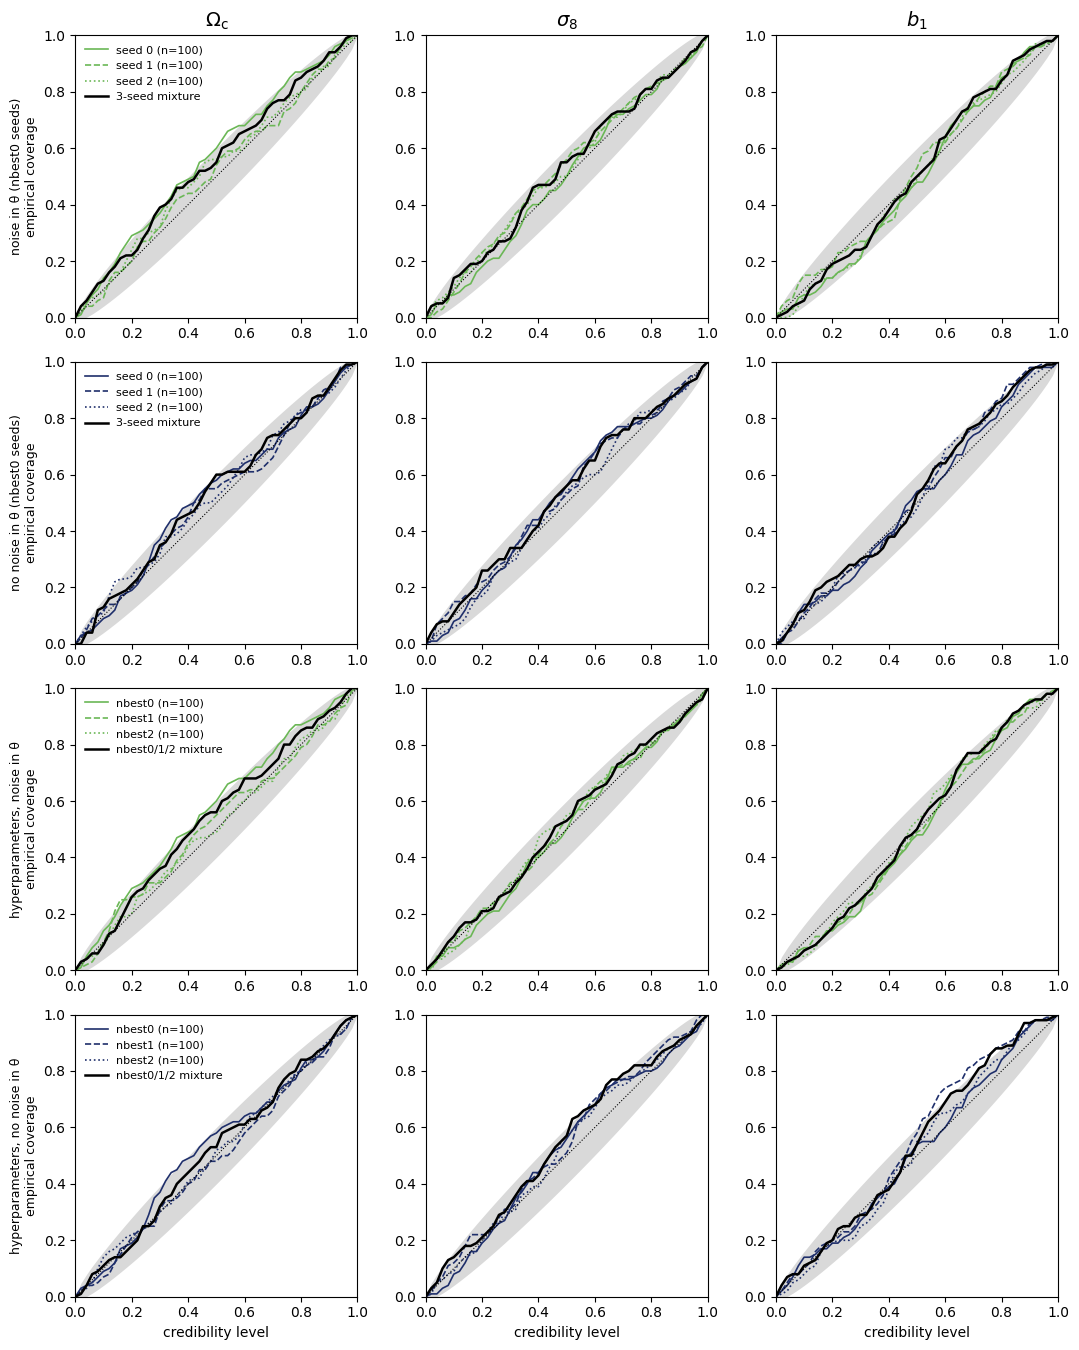

In [9]:
band = 2 * np.sqrt(CRED * (1 - CRED) / len(idxs_cov))
member_ls = ["-", "--", ":"]
fig, axes = plt.subplots(len(COV_GROUPS), 3, figsize=(11, 3.4 * len(COV_GROUPS)))
for r, (glabel, sfxs) in enumerate(COV_GROUPS.items()):
    is_hp = glabel.startswith("hyperparameters")
    color = COLOR_NONOISE if "no noise" in glabel else COLOR_NOISE
    curves = []
    for i, sfx in enumerate(sfxs):
        s = samples_cov[sfx]
        if s is None:
            continue
        pp, n = pp_curve(s)
        lab = (f"nbest{sfx[0]}" if is_hp else f"seed {i}") + f" (n={n})"
        curves.append(s)
        for c in range(3):
            axes[r, c].plot(CRED, pp[c], color=color, ls=member_ls[i], lw=1.2, label=lab if c == 0 else None)
    if len(curves) == len(sfxs):
        pp, _ = pp_curve(mixture(curves))
        for c in range(3):
            axes[r, c].plot(CRED, pp[c], color="k", lw=1.8, label=("nbest0/1/2" if is_hp else "3-seed") + " mixture" if c == 0 else None)
    for c, p in enumerate(PP_PARAMS):
        ax = axes[r, c]
        ax.fill_between(CRED, CRED - band, CRED + band, color="0.85", lw=0)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        if r == 0:
            ax.set_title(PP_LABELS[p], fontsize=14)
        if r == len(COV_GROUPS) - 1:
            ax.set_xlabel("credibility level")
    axes[r, 0].set_ylabel(f"{glabel}\nempirical coverage", fontsize=9)
    axes[r, 0].legend(fontsize=8, loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"coverage_pp_{SUB}.pdf", bbox_inches="tight")
plt.show()

In [10]:
# Summary per model / mixture: mean (coverage − credibility) over levels (+ = conservative, − = overconfident),
# max |coverage − credibility|, coverage of the central 68% and 95% intervals, median posterior σ
rows = []
def summarize(label, s):
    pp, n = pp_curve(s)
    row = {"model": label, "n": n}
    for c, p in enumerate(PP_PARAMS):
        d = pp[c] - CRED
        row[(p, "mean Δ")] = d.mean()
        row[(p, "max |Δ|")] = np.abs(d).max()
        row[(p, "cov68")] = np.interp(0.68, CRED, pp[c])
        row[(p, "cov95")] = np.interp(0.95, CRED, pp[c])
        row[(p, "med σ")] = np.nanmedian(s[:, :, c].std(axis=0))
    rows.append(row)
for glabel, sfxs in COV_GROUPS.items():
    arrs = [samples_cov[sfx] for sfx in sfxs]
    for sfx, s in zip(sfxs, arrs):
        if s is not None and not any(r_["model"] == sfx for r_ in rows):
            summarize(sfx, s)
    if all(a is not None for a in arrs):
        summarize(f"mixture: {glabel}", mixture(arrs))
if not rows:
    print("no coverage samples yet")
else:
    df_cov = pd.DataFrame(rows).set_index("model")
    df_cov.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in df_cov.columns])
    print(f"{len(idxs_cov)} obs; ±2σ binomial scatter on cov68 ≈ ±{2*np.sqrt(.68*.32/len(idxs_cov)):.2f}, on cov95 ≈ ±{2*np.sqrt(.95*.05/len(idxs_cov)):.2f}")
    display(df_cov.round(3))

100 obs; ±2σ binomial scatter on cov68 ≈ ±0.09, on cov95 ≈ ±0.04


n omega_cold                       \
                                                 mean Δ max |Δ| cov68  cov95   
model                                                                          
0                                        100      0.065    0.12  0.75  0.975   
0_seed1                                  100      0.013    0.06  0.68  0.970   
0_seed2                                  100      0.025    0.09  0.71  0.960   
mixture: noise in θ (nbest0 seeds)       100      0.048    0.10  0.74  0.975   
0_nonoise                                100      0.028    0.10  0.69  0.970   
0_nonoise_seed1                          100      0.019    0.09  0.64  0.980   
0_nonoise_seed2                          100      0.027    0.08  0.69  0.955   
mixture: no noise in θ (nbest0 seeds)    100      0.031    0.10  0.73  0.980   
1                                        100      0.017    0.09  0.68  0.935   
2                                        100      0.006    0.04  0.67  0.950   
mixture: hyperparameters, noise in θ     100      0.042    0.09  0.71  0.965   
1_nonoise                                100     -0.011    0.04  0.64  0.940   
2_nonoise                                100      0.006    0.04  0.69  0.940   
mixture: hyperparameters, no noise in θ  100      0.015    0.06  0.67  0.970   

                                               sigma8_cold                \
                                         med σ      mean Δ max |Δ| cov68   
model                                                                      
0                                        0.019      -0.002    0.06  0.72   
0_seed1                                  0.015       0.024    0.07  0.72   
0_seed2                                  0.016       0.021    0.06  0.71   
mixture: noise in θ (nbest0 seeds)       0.017       0.022    0.08  0.73   
0_nonoise                                0.016       0.023    0.10  0.77   
0_nonoise_seed1                          0.016       0.029    0.09  0.73   
0_nonoise_seed2                          0.016       0.005    0.06  0.73   
mixture: no noise in θ (nbest0 seeds)    0.016       0.031    0.09  0.74   
1                                        0.015       0.009    0.05  0.72   
2                                        0.015       0.015    0.07  0.72   
mixture: hyperparameters, noise in θ     0.017       0.015    0.06  0.73   
1_nonoise                                0.016       0.037    0.10  0.76   
2_nonoise                                0.016       0.022    0.08  0.75   
mixture: hyperparameters, no noise in θ  0.017       0.044    0.11  0.77   

                                                          b1                \
                                         cov95  med σ mean Δ max |Δ| cov68   
model                                                                        
0                                        0.930  0.027 -0.005    0.09  0.73   
0_seed1                                  0.935  0.026  0.016    0.07  0.73   
0_seed2                                  0.940  0.027 -0.005    0.09  0.75   
mixture: noise in θ (nbest0 seeds)       0.945  0.028  0.007    0.08  0.74   
0_nonoise                                0.935  0.027  0.012    0.06  0.72   
0_nonoise_seed1                          0.950  0.028  0.025    0.10  0.75   
0_nonoise_seed2                          0.935  0.027  0.020    0.09  0.76   
mixture: no noise in θ (nbest0 seeds)    0.935  0.027  0.028    0.08  0.76   
1                                        0.940  0.027 -0.004    0.07  0.73   
2                                        0.935  0.027  0.010    0.09  0.76   
mixture: hyperparameters, noise in θ     0.940  0.028  0.006    0.09  0.77   
1_nonoise                                0.960  0.028  0.047    0.14  0.81   
2_nonoise                                0.945  0.027  0.012    0.07  0.72   
mixture: hyperparameters, no noise in θ  0.945  0.028  0.036    0.10  0.75   

                                                       
      

### 5b. Seed mixture for each hyperparameter set

One curve per hyperparameter set: the 3-seed mixture (seeds 0–2) of nbest0, nbest1 and nbest2, plus the 9-network mixture of all of them (black). The v1 rank-10 and rank-20 trials (noise in θ, single seed) are grey. If the three seed mixtures agree, the ensembling choice after the v2 sweep (top-3 sets vs seeds of the top set) doesn't matter for calibration.


missing: []


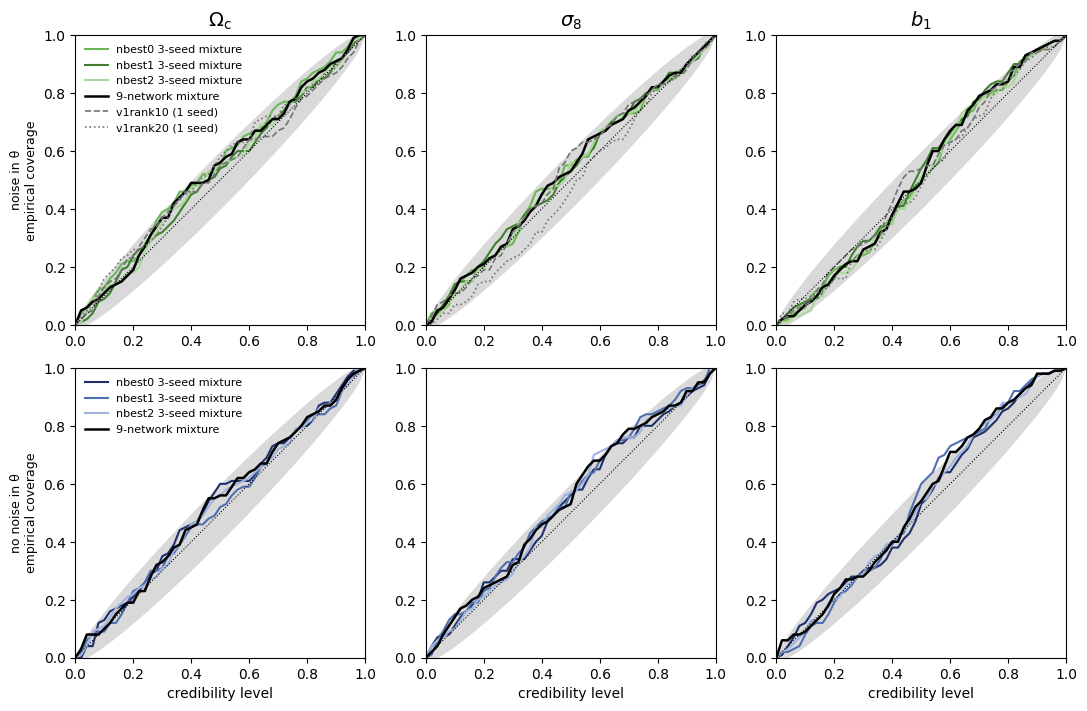

n omega_cold                              \
                                       mean Δ max |Δ| cov68  cov95  med σ   
model                                                                       
noise in θ: nbest0 3-seed      100      0.048    0.10  0.74  0.975  0.017   
noise in θ: nbest1 3-seed      100      0.017    0.05  0.71  0.955  0.016   
noise in θ: nbest2 3-seed      100      0.023    0.07  0.69  0.965  0.017   
noise in θ: 9-network          100      0.034    0.09  0.71  0.970  0.016   
no noise in θ: nbest0 3-seed   100      0.031    0.10  0.73  0.980  0.016   
no noise in θ: nbest1 3-seed   100      0.014    0.05  0.71  0.965  0.016   
no noise in θ: nbest2 3-seed   100      0.021    0.07  0.69  0.960  0.016   
no noise in θ: 9-network       100      0.025    0.09  0.71  0.970  0.016   
noise in θ: v1rank10_nfcvgas4  100      0.019    0.08  0.65  0.930  0.016   
noise in θ: v1rank20_qiost01x  100      0.039    0.08  0.72  0.955  0.016   

                              sigma8_cold                                 b1  \
                                   mean Δ max |Δ| cov68  cov95  med σ mean Δ   
model                                                                          
noise in θ: nbest0 3-seed           0.022    0.08  0.73  0.945  0.028  0.007   
noise in θ: nbest1 3-seed           0.024    0.06  0.71  0.940  0.027  0.019   
noise in θ: nbest2 3-seed           0.017    0.07  0.72  0.940  0.027 -0.000   
noise in θ: 9-network               0.025    0.08  0.71  0.950  0.027  0.012   
no noise in θ: nbest0 3-seed        0.031    0.09  0.74  0.935  0.027  0.028   
no noise in θ: nbest1 3-seed        0.045    0.09  0.75  0.945  0.027  0.038   
no noise in θ: nbest2 3-seed        0.035    0.12  0.76  0.950  0.027  0.031   
no noise in θ: 9-network            0.040    0.10  0.77  0.950  0.027  0.037   
noise in θ: v1rank10_nfcvgas4       0.024    0.10  0.73  0.945  0.028  0.018   
noise in θ: v1rank20_qiost01x      -0.029    0.08  0.64  0.950  0.028 -0.006   

                                                           
                              max |Δ| cov68  cov95  med σ  
model                                                      
noise in θ: nbest0 3-seed        0.08  0.74  0.975  0.109  
noise in θ: nbest1 3-seed        0.09  0.77  0.975  0.110  
noise in θ: nbest2 3-seed        0.09  0.76  0.975  0.112  
noise in θ: 9-network            0.09  0.76  0.975  0.111  
no noise in θ: nbest0 3-seed     0.08  0.76  0.985  0.108  
no noise in θ: nbest1 3-seed     0.13  0.77  0.985  0.111  
no noise in θ: nbest2 3-seed     0.10  0.77  0.985  0.113  
no noise in θ: 9-network         0.11  0.77  0.985  0.112  
noise in θ: v1rank10_nfcvgas4    0.07  0.71  0.955  0.113  
noise in θ: v1rank20_qiost01x    0.08  0.71  0.960  0.113

In [11]:
for nb in (1, 2):
    for noise in ("", "_nonoise"):
        for sd in (1, 2):
            samples_cov.setdefault(f"{nb}{noise}{SEED_SUFFIX[sd]}", load_cov(f"{nb}{noise}{SEED_SUFFIX[sd]}"))
for t in V1RANK:
    samples_cov[t] = load_cov(t)
print("missing:", [k for k, v in samples_cov.items() if v is None])

fig, axes = plt.subplots(2, 3, figsize=(11, 7.2))
for r, (noise, lab) in enumerate((("", "noise in θ"), ("_nonoise", "no noise in θ"))):
    MIX_COLORS = ({0: COLOR_PKPGM, 1: "#3F7F2F", 2: "#A8D89A"} if noise == ""
                  else {0: COLOR_PKPGM_DARK, 1: "#4F6FB0", 2: "#9FB4E0"})
    all9 = []
    for nb in (0, 1, 2):
        arrs = [samples_cov.get(f"{nb}{noise}{SEED_SUFFIX[sd]}") for sd in (0, 1, 2)]
        if any(a is None for a in arrs):
            continue
        all9 += arrs
        pp, n = pp_curve(mixture(arrs))
        for c in range(3):
            axes[r, c].plot(CRED, pp[c], color=MIX_COLORS[nb], lw=1.5, label=f"nbest{nb} 3-seed mixture" if c == 0 else None)
    if len(all9) == 9:
        pp, _ = pp_curve(mixture(all9))
        for c in range(3):
            axes[r, c].plot(CRED, pp[c], color="k", lw=1.8, label="9-network mixture" if c == 0 else None)
    if noise == "":
        for t, ls in zip(V1RANK, ("--", ":")):
            if samples_cov[t] is not None:
                pp, _ = pp_curve(samples_cov[t])
                for c in range(3):
                    axes[r, c].plot(CRED, pp[c], color="0.45", ls=ls, lw=1.2, label=t.split("_")[0] + " (1 seed)" if c == 0 else None)
    for c, p in enumerate(PP_PARAMS):
        ax = axes[r, c]
        ax.fill_between(CRED, CRED - band, CRED + band, color="0.85", lw=0)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        if r == 0:
            ax.set_title(PP_LABELS[p], fontsize=14)
        if r == 1:
            ax.set_xlabel("credibility level")
    axes[r, 0].set_ylabel(f"{lab}\nempirical coverage", fontsize=9)
    axes[r, 0].legend(fontsize=8, loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"coverage_pp_seedmixtures_{SUB}.pdf", bbox_inches="tight")
plt.show()

rows = []
for noise, lab in (("", "noise in θ"), ("_nonoise", "no noise in θ")):
    all9 = []
    for nb in (0, 1, 2):
        arrs = [samples_cov.get(f"{nb}{noise}{SEED_SUFFIX[sd]}") for sd in (0, 1, 2)]
        if all(a is not None for a in arrs):
            all9 += arrs
            summarize(f"{lab}: nbest{nb} 3-seed", mixture(arrs))
    if len(all9) == 9:
        summarize(f"{lab}: 9-network", mixture(all9))
for t in V1RANK:
    if samples_cov[t] is not None:
        summarize(f"noise in θ: {t}", samples_cov[t])
df_mix = pd.DataFrame(rows).set_index("model")
df_mix.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in df_mix.columns])
display(df_mix.round(3))
